# SMS Spam Detection

A simple NLP pipeline to classify SMS messages as spam or ham, using the SMS Spam Collection dataset. Covers text cleaning, tokenization, stopword removal, lemmatization, POS tagging, feature extraction (BoW, TF-IDF, N-grams), and a Naive Bayes classifier.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")


## 1. Load the data

In [2]:
df=pd.read_csv("../data/spam.csv",encoding='latin-1')

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Quick look at the data

Checking class balance, duplicates and missing values before touching anything.

In [4]:
df['label'].value_counts()


label
ham     4825
spam     747
Name: count, dtype: int64

In [5]:
df.duplicated().sum()

np.int64(403)

In [6]:
df.isnull().sum()

label    0
text     0
dtype: int64

In [7]:
df.drop_duplicates(inplace=True)

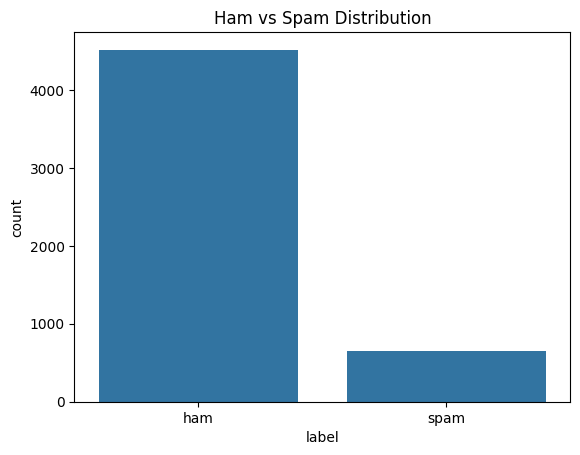

In [8]:
sns.countplot(x='label', data=df)
plt.title("Ham vs Spam Distribution")
plt.show()

## 3. Cleaning the text

Stripping URLs, numbers and punctuation with regex, then lowercasing everything.

In [9]:
import re

def clean_text(text):
    text = re.sub(r'http\S+', '', text)  
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    text = text.lower()                   
    text = text.strip()                   
    return text


In [10]:
df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].head()


,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives aro...


## 4. Tokenization

In [11]:
import nltk
df['tokens'] = df['clean_text'].apply(nltk.word_tokenize)
df[['clean_text', 'tokens']].head()


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, until, jurong, point, crazy, available, o..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, in, a, wkly, comp, to, win, fa, ..."
3,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t..."
4,nah i don t think he goes to usf he lives aro...,"[nah, i, don, t, think, he, goes, to, usf, he,..."


## 5. Removing stopwords

In [12]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

df['tokens'] = df['tokens'].apply(
    lambda x: [w for w in x if w not in stop_words]
)

df[['clean_text', 'tokens']].head()


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,u dun say so early hor u c already then say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah i don t think he goes to usf he lives aro...,"[nah, think, goes, usf, lives, around, though]"


In [13]:
print(stop_words)


{"i'll", "mightn't", 'too', 'at', 'didn', "i'm", 'wouldn', 'how', 'their', 'your', 'yourselves', 'did', 'does', 'by', "hasn't", "we're", 'where', 'against', "haven't", 'about', 'he', 'on', 'shouldn', 'same', 'its', 'i', 'more', 'for', 'which', 'are', 'me', 'ourselves', 'll', 'weren', "wasn't", 'yourself', 'hasn', 'needn', "you're", 'am', "mustn't", "shouldn't", 'with', "they've", 'we', 'when', 'him', 'hadn', 'herself', 'under', 'haven', 'above', 'further', 'below', 'this', 'than', 'mustn', 'the', 'what', 'nor', 'is', 'while', 'and', 'who', 'such', "couldn't", 'or', 'a', 'won', "they'll", 'were', 'themselves', "hadn't", "don't", 'those', 'other', "you'd", "she's", 's', "didn't", "doesn't", 'out', 'hers', 'some', "it'll", 'ma', 'as', "aren't", 'himself', 'any', 'no', 'that', 'now', 'had', 'to', 'will', 'she', "we've", 'before', 'own', 'been', 'here', "it's", 'my', "weren't", 'few', "shan't", 'being', 'myself', 'during', 'of', 'you', 'down', 'it', 'because', 'isn', 'itself', "she'll", 'an

## 6. Lemmatization

In [14]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

df['tokens'] = df['tokens'].apply(
    lambda x: [lemmatizer.lemmatize(w) for w in x]
)

df[['clean_text', 'tokens']].head()


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,u dun say so early hor u c already then say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah i don t think he goes to usf he lives aro...,"[nah, think, go, usf, life, around, though]"


## 7. POS tagging

The lemmatizer needs to know if a word is a verb, noun or adjective to lemmatize it correctly.

In [15]:
sample = df['tokens'][0]
print(nltk.pos_tag(sample))


[('go', 'VB'), ('jurong', 'JJ'), ('point', 'NN'), ('crazy', 'NN'), ('available', 'JJ'), ('bugis', 'NN'), ('n', 'RB'), ('great', 'JJ'), ('world', 'NN'), ('la', 'NN'), ('e', 'VBP'), ('buffet', 'JJ'), ('cine', 'NN'), ('got', 'VBD'), ('amore', 'RB'), ('wat', 'JJ')]


In [16]:
from nltk.corpus import wordnet

def get_wordnet_pos(tag):
    if tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN


In [17]:
def lemmatize_with_pos(tokens):
    tagged = nltk.pos_tag(tokens)
    return [lemmatizer.lemmatize(w, get_wordnet_pos(tag)) 
            for w, tag in tagged]

df['tokens'] = df['tokens'].apply(lemmatize_with_pos)
df[['clean_text', 'tokens']].head()


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,u dun say so early hor u c already then say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah i don t think he goes to usf he lives aro...,"[nah, think, go, usf, life, around, though]"


In [18]:
df['processed'] = df['tokens'].apply(lambda x: ' '.join(x))
df[['clean_text', 'processed']].head()


,clean_text,processed
0,go until jurong point crazy available only ...,go jurong point crazy available bugis n great ...
1,ok lar joking wif u oni,ok lar joking wif u oni
2,free entry in a wkly comp to win fa cup fina...,free entry wkly comp win fa cup final tkts st ...
3,u dun say so early hor u c already then say,u dun say early hor u c already say
4,nah i don t think he goes to usf he lives aro...,nah think go usf life around though


## 8. Train/test split

In [19]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['processed'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

print(X_train_text.shape, X_test_text.shape)


(4135,) (1034,)


## 9. Feature extraction — TF-IDF

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print(X_train_tfidf.shape, X_test_tfidf.shape)


(4135, 5719) (1034, 5719)


## 10. Training the model

Naive Bayes — the standard baseline for text classification.

In [21]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


## 11. Evaluation

In [22]:
y_pred = model.predict(X_test_tfidf)

In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9642166344294004


In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.98      0.73      0.84       131

    accuracy                           0.96      1034
   macro avg       0.97      0.87      0.91      1034
weighted avg       0.96      0.96      0.96      1034



## Extra: handling the imbalance

Recall on spam was only 0.73 because ham messages dominate the dataset. Tried oversampling the minority class to see if it helps.

In [25]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_bal, y_train_bal = ros.fit_resample(X_train_tfidf, y_train)

print(y_train_bal.value_counts())


label
ham     3613
spam    3613
Name: count, dtype: int64


In [26]:
model_balanced = MultinomialNB()
model_balanced.fit(X_train_bal, y_train_bal)

y_pred_balanced = model_balanced.predict(X_test_tfidf)


In [27]:
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

         ham       0.99      0.96      0.97       903
        spam       0.76      0.96      0.85       131

    accuracy                           0.96      1034
   macro avg       0.88      0.96      0.91      1034
weighted avg       0.96      0.96      0.96      1034



## Bonus 1 — BoW vs TF-IDF

In [28]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer()

X_train_bow = bow_vectorizer.fit_transform(X_train_text)
X_test_bow = bow_vectorizer.transform(X_test_text)

print(X_train_bow.shape, X_test_bow.shape)

(4135, 5719) (1034, 5719)


In [29]:
model_bow = MultinomialNB()
model_bow.fit(X_train_bow, y_train)

y_pred_bow = model_bow.predict(X_test_bow)

print(classification_report(y_test, y_pred_bow))

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.94      0.93      0.93       131

    accuracy                           0.98      1034
   macro avg       0.96      0.96      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Bonus 2 — Unigram vs Unigram+Bigram

In [30]:
bigram_vectorizer = CountVectorizer(ngram_range=(1, 2))

X_train_bigram = bigram_vectorizer.fit_transform(X_train_text)
X_test_bigram = bigram_vectorizer.transform(X_test_text)

print(X_train_bigram.shape, X_test_bigram.shape)

(4135, 29408) (1034, 29408)


In [31]:
model_bigram = MultinomialNB()
model_bigram.fit(X_train_bigram, y_train)

y_pred_bigram = model_bigram.predict(X_test_bigram)

print(classification_report(y_test, y_pred_bigram))


              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.96      0.92      0.94       131

    accuracy                           0.98      1034
   macro avg       0.97      0.96      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Conclusion

Best result came from BoW with unigrams + bigrams (F1 = 0.94, accuracy = 0.98). TF-IDF actually did worse with Naive Bayes here — it down-weights words like "free" and "win" just for being common across spam messages, even though that's exactly what makes them useful signals.

Oversampling the minority class pushed spam recall up to 0.96, but precision dropped to 0.76. So it's a real tradeoff, not a free win — which model is "better" depends on whether missing spam or misflagging a normal message is worse for the use case.